In [309]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import numpy as np
import os
import glob
from scipy.signal import savgol_filter
import pandas as pd
import seaborn as sns
import math
from scipy.stats import exponnorm
import scipy.special as sse
from scipy.optimize import curve_fit
from scipy import stats
#from pomegranate import *
from sklearn.metrics import mean_squared_error
from sklearn.mixture import GaussianMixture
from scipy.stats import norm
from scipy.special import rel_entr
from sklearn.neighbors import KernelDensity

In [78]:
file_location = os.path.join('C:\\Users\\Austin\\Desktop\\cell_model\\fig_data', '*imt*')
filenames = glob.glob(file_location)

In [189]:
filenames

['C:\\Users\\Austin\\Desktop\\cell_model\\fig_data\\02kpa_dmso_imt_190118.csv',
 'C:\\Users\\Austin\\Desktop\\cell_model\\fig_data\\02kpa_erl_imt_190118.csv',
 'C:\\Users\\Austin\\Desktop\\cell_model\\fig_data\\06kpa_dmso_imt_181017.csv',
 'C:\\Users\\Austin\\Desktop\\cell_model\\fig_data\\06kpa_erl_imt_181017.csv',
 'C:\\Users\\Austin\\Desktop\\cell_model\\fig_data\\4kpa_dmso_imt_190118.csv',
 'C:\\Users\\Austin\\Desktop\\cell_model\\fig_data\\4kpa_erl_imt_190118.csv',
 'C:\\Users\\Austin\\Desktop\\cell_model\\fig_data\\55kpa_dmso_imt_181017.csv',
 'C:\\Users\\Austin\\Desktop\\cell_model\\fig_data\\55kpa_erl_imt_181017.csv']

In [6]:
IMTs = []
for f in filenames:
    tmp_df = pd.read_csv(f)
    tmp_df = tmp_df.replace(to_replace=-1, value=np.nan)
    IMTs.append(tmp_df)

ii=0
for df in IMTs:
    df["IMT"] = df["Division"] - df["Mitotic Frame"]
    df["G1"] = df["Green On"] - df["Mitotic Frame"]
    df["S-M"] = df["Division"] - df["Green On"]
    if ii == 2 or ii == 3 or ii == 6 or ii == 7:
        df["IMT_t"] = df["IMT"] * (32/60)
        df["G1_t"] = df["G1"] * (32/60)
        df["S-M_t"] = df["S-M"] * (32/60)
    else:
        df["IMT_t"] = df["IMT"] * (20/60)
        df["G1_t"] = df["G1"] * (20/60)
        df["S-M_t"] = df["S-M"] * (20/60)
    #df = df[(df["IMT_t"] ==27)].reset_index(drop=True)
    ii+=1
    
stiffs = [0.2, 0.2, 0.6, 0.6, 4, 4, 55, 55]
ii=0
for df in IMTs:
    tmp_stiff = np.ones(len(df))*stiffs[ii]
    df.insert(0, "Stiffness", tmp_stiff)
    if ii % 2 == 0:
        df["Drug"] = "DMSO"
    else:
        df["Drug"] = "ERL"    
    ii+=1

all_IMTs = pd.concat(IMTs, ignore_index=True, sort=False)
centers = np.arange(0.5, 100.5, 1)

In [7]:
def emg_fit_func(x, l, s, m):
    return 0.5*l*np.exp(0.5*l*(2*m+l*s*s-2*x))*sse.erfc((m+l*s*s-x)/(np.sqrt(2)*s)) # exponential gaussian

In [28]:
def calculate_aic(LL, num_params):
    aic = 2*num_params - 2*LL
    return aic

In [196]:
def calculate_bic(LL, num_params, samp_size):
    bic = num_params*math.log(samp_size) - 2*LL
    return bic

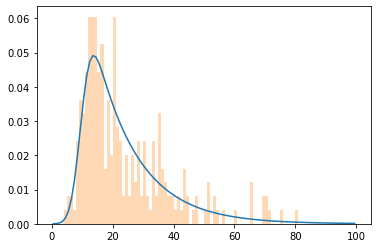

In [354]:
data = np.array(IMTs[5]["G1_t"])
data = data[~np.isnan(data)]
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
LLH = exponnorm.logpdf(data,*params).sum()
emg_aic = calculate_aic(LLH, 3)
fitted_curve=list(emg_fit_func(centers,exp_c,params[0],params[1]))
plt.plot(centers, fitted_curve)
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = plt.stairs(h, edges, fill=True, alpha=0.3)

In [164]:
x = np.array(IMTs[5]["G1_t"])
x = x[~np.isnan(x)]
x = x.reshape(-1,1)
aics = []
min_aic = 0
counter=1
for i in range (3): # test the AIC/BIC metric between 1 and 10 components
    gmm = GaussianMixture(n_components = counter, max_iter=1000, random_state=0, covariance_type = 'full')
    labels = gmm.fit(x).predict(x)
    aic = gmm.aic(x)
    aics.append(aic)
    if aic < min_aic or min_aic == 0:
        min_aic = aic
        opt_aic = counter
    counter += 1

C:\Users\Austin\anaconda3\envs\stoch_cell\lib\site-packages\sklearn\cluster\_kmeans.py:1036: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [120]:
aics

[1722.5653526308934, 1693.1459962609654, 1681.155032397871, 1681.6363694347153]

In [158]:
def plot_mixture(gmm, X, show_legend=True, ax=None):
    if ax is None:
        ax = plt.gca()

 # Compute PDF of whole mixture
    x = np.arange(0.5, 100.5, 1)
    logprob = gmm.score_samples(x.reshape(-1, 1))
    pdf = np.exp(logprob)

 # Compute PDF for each component
    responsibilities = gmm.predict_proba(x.reshape(-1, 1))
    pdf_individual = responsibilities * pdf[:, np.newaxis]
    
 # Calculate mse and aic
#     h, edges =np.histogram(X, bins=range(0,101), density=True)
#     mse = mean_squared_error(h, pdf)
#     aic = calculate_aic(len(h), mse, 3)
    
 # Plot data histogram
    ax.hist(X, bins=range(0,101), density=True, histtype='stepfilled', alpha=0.4, label='Data')

 # Plot PDF of whole model
    ax.plot(x, pdf, '-k', label='Mixture PDF')

 # Plot PDF of each component
    ax.plot(x, pdf_individual, '--', label='Component PDF')
    ax.set_xlabel('$x$')
    ax.set_ylabel('$p(x)$')
    if show_legend:
        ax.legend()
        

In [397]:
x = np.array(IMTs[5]["G1_t"])
x = x[~np.isnan(x)]
x = x.reshape(-1,1)

# Fit models with 1-10 components
k_arr = np.arange(3) + 1
models = [GaussianMixture(n_components=k).fit(x) for k in k_arr]


C:\Users\Austin\anaconda3\envs\stoch_cell\lib\site-packages\sklearn\cluster\_kmeans.py:1036: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


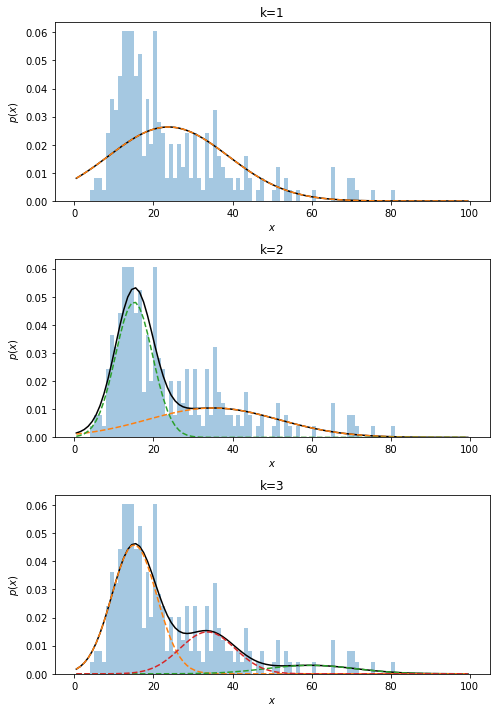

In [398]:
_, axes = plt.subplots(3, 1, figsize = (7,10))
for gmm, ax in zip(models, axes.ravel()):
    plot_mixture(gmm, x, show_legend=False, ax=ax)
    ax.set_title(f'k={gmm.n_components}')
plt.tight_layout()


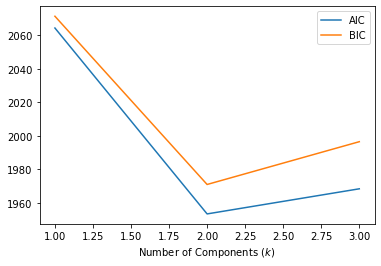

In [167]:
# Compute metrics to determine best hyperparameter
AIC = [m.aic(x) for m in models]
BIC = [m.bic(x) for m in models]
# Plot these metrics
plt.plot(k_arr, AIC, label='AIC')
plt.plot(k_arr, BIC, label='BIC')
plt.xlabel('Number of Components ($k$)')
plt.legend()

In [200]:
def calc_aics(data):
    x = np.array(data)
    x = x[~np.isnan(x)]
    x_res = x.reshape(-1,1)

    # Fit models with 1-10 components
    k_arr = np.arange(3) + 1
    models = [GaussianMixture(n_components=k).fit(x_res) for k in k_arr]
    # Compute metrics to determine best hyperparameter
    AIC = [m.aic(x_res) for m in models]
    BIC = [m.bic(x_res) for m in models]
    
    params = exponnorm.fit(x)
    exp_c = 1/(params[0]*params[2])
    LLH = exponnorm.logpdf(x,*params).sum()
    emg_aic = calculate_aic(LLH, 3)
    emg_bic = calculate_bic(LLH, 3, len(x))
    AIC.append(emg_aic)
    BIC.append(emg_bic)
    
    return AIC, BIC

In [230]:
[AICs, BICs] = calc_aics(IMTs[5]["IMT_t"])

C:\Users\Austin\anaconda3\envs\stoch_cell\lib\site-packages\sklearn\cluster\_kmeans.py:1036: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


C:\Users\Austin\anaconda3\envs\stoch_cell\lib\site-packages\sklearn\cluster\_kmeans.py:1036: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


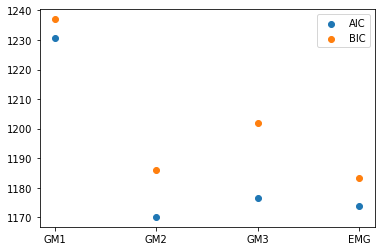

In [390]:
[AICs, BICs] = calc_aics(IMTs[4]["IMT_t"])
labels = ['GM1', 'GM2', 'GM3', 'EMG']
x = np.arange(len(labels))  # the label locations
width = 0.35  # the width of the bars

fig, ax = plt.subplots()
rects1 = ax.scatter(x, AICs, label='AIC')
rects2 = ax.scatter(x, BICs, label='BIC')
ax.set_xticks(x, labels)
ax.legend()

In [340]:
def calc_kl(data):
    x = np.array(data)
    x = x[~np.isnan(x)]
    x_res = x.reshape(-1,1)
    h, edges =np.histogram(data, bins=range(0,101), density=True)

    # Fit models with 3 components
    k_arr = np.arange(3) + 1
    models = [GaussianMixture(n_components=k).fit(x_res) for k in k_arr]
    
    kl = []
    for model in models:
        vals = np.arange(0.5, 100.5, 1)
        logprob = model.score_samples(vals.reshape(-1, 1))
        pdf = np.exp(logprob)
        kl.append(sum(rel_entr(h, pdf)))

    
    params = exponnorm.fit(x)
    exp_c = 1/(params[0]*params[2])
    fitted_curve=list(emg_fit_func(centers,exp_c,params[0],params[1]))
    kl.append(sum(rel_entr(h, fitted_curve)))

    
    return kl

C:\Users\Austin\anaconda3\envs\stoch_cell\lib\site-packages\sklearn\cluster\_kmeans.py:1036: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


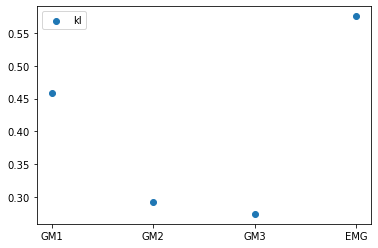

In [388]:
kls = calc_kl(IMTs[5]["IMT_t"])

labels = ['GM1', 'GM2', 'GM3', 'EMG']
x = np.arange(len(labels))  # the label locations

fig, ax = plt.subplots()
rects1 = ax.scatter(x, kls, label='kl')
ax.set_xticks(x, labels)
ax.legend()

C:\Users\Austin\anaconda3\envs\stoch_cell\lib\site-packages\sklearn\cluster\_kmeans.py:1036: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Austin\anaconda3\envs\stoch_cell\lib\site-packages\sklearn\cluster\_kmeans.py:1036: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


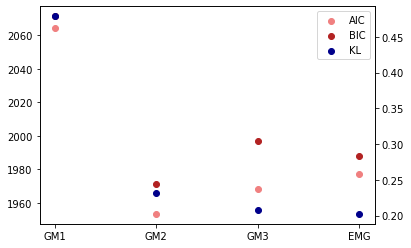

In [399]:
[AICs, BICs] = calc_aics(IMTs[5]["G1_t"])
kls = calc_kl(IMTs[5]["G1_t"])
labels = ['GM1', 'GM2', 'GM3', 'EMG']
x = np.arange(len(labels))  # the label locations

ax = plt.subplot()
aic_v = ax.scatter(x, AICs, label='AIC', color='lightcoral')
bic_v = ax.scatter(x, BICs, label='BIC', color='firebrick')
ax.set_xticks(x, labels)
ax2 = ax.twinx()
kl_v = ax2.scatter(x, kls, label='kl', color='darkblue')
plt.legend([aic_v, bic_v, kl_v], ["AIC", "BIC", "KL"])


In [375]:
kls

[0.7948589006575859,
 0.24971575322182196,
 0.17452981771795253,
 0.45267237065851557]